#Detecção de Fraudes Financeiras

### Aqui, carregamos um dataset da internet para trabalhar

In [3]:
import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Classificação Desbalanceada
## Feature Engineering

### Aqui, criamos versões transformadas da variável Amount para lidar com assimetria e escala, separa features do alvo e divide os dados em treino/teste de forma estratificada — preservando a proporção de fraudes, essencial num dataset desbalanceado.

In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df["Amount_log"] = np.log1p(df["Amount"])
scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

x = df.drop("Class", axis=1)
y = df["Class"]

# 30% dos dados servem para teste; 70% dos dados para treino
# stratify=y garante que a proporção de fraudes e não fraudes sejam mantidas
# random_state=42 serve para reprodutibilidade
x_train, x_test, y_train, y_test = train_test_split(x, y, stratify=y, test_size=0.3, random_state=42)

# Logistics Regression

### Aqui, treinamos um modelo de Regressão Logística nos dados de treino e geramos, para o conjunto de teste, tanto as classes previstas quanto as probabilidades de fraude.

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_probs = model.predict_proba(x_test)[:,1]

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.66      0.73       148

    accuracy                           1.00     85443
   macro avg       0.92      0.83      0.87     85443
weighted avg       1.00      1.00      1.00     85443



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Gráfico: Curva ROC

### Essa parte calcula e plota a curva ROC do modelo e imprime a AUC, que mede a capacidade do modelo de separar fraudes de transações normais.

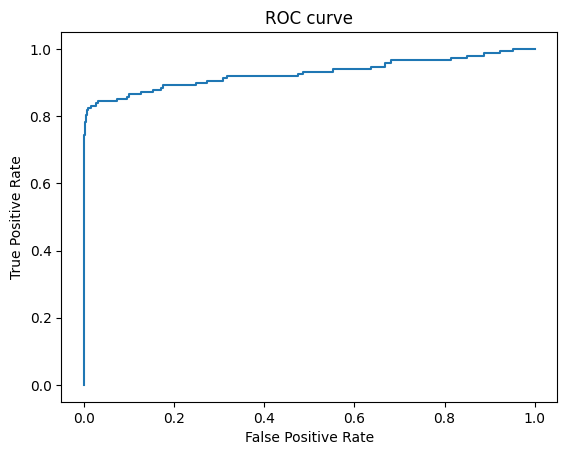


AUC:  0.9272042339543365


In [6]:
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.plot(fpr, tpr)
plt.title('ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

print("\nAUC: ", roc_auc_score(y_test, y_probs))

# Gráfico: Precision Recall Curve

### Essa é a parte que calcula e plota a curva Precision-Recall, que mostra o trade-off entre precisão e recall ao longo dos limiares.

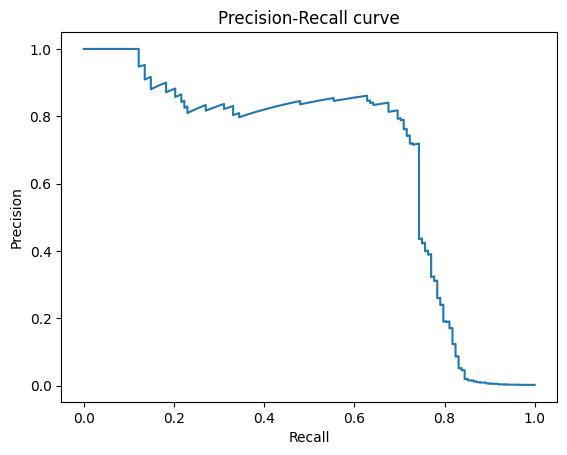

In [12]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_probs)

plt.plot(recall, precision)
plt.title('Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

# Balanceamento de dados
## Undersampling


### Aqui, um undersampling é feito, ou seja, criamos uma versão balanceada do dataset: mantendo todas as fraudes e sorteia igual número de transações normais, juntando tudo.
### O trade-off aqui se dá pelo fato de que a fim de balancear de balancear o dataset, perdemos muitos dados.

In [13]:
fraudes = df[df["Class"] == 1]
normais = df[df["Class"] == 0].sample(len(fraudes), random_state=42)

df_under = pd.concat([fraudes, normais])

print(df_under.head())

        Time        V1        V2        V3        V4        V5        V6  \
541    406.0 -2.312227  1.951992 -1.609851  3.997906 -0.522188 -1.426545   
623    472.0 -3.043541 -3.157307  1.088463  2.288644  1.359805 -1.064823   
4920  4462.0 -2.303350  1.759247 -0.359745  2.330243 -0.821628 -0.075788   
6108  6986.0 -4.397974  1.358367 -2.592844  2.679787 -1.128131 -1.706536   
6329  7519.0  1.234235  3.019740 -4.304597  4.732795  3.624201 -1.357746   

            V7        V8        V9  ...       V23       V24       V25  \
541  -2.537387  1.391657 -2.770089  ... -0.465211  0.320198  0.044519   
623   0.325574 -0.067794 -0.270953  ...  1.375966 -0.293803  0.279798   
4920  0.562320 -0.399147 -0.238253  ...  0.172726 -0.087330 -0.156114   
6108 -3.496197 -0.248778 -0.247768  ... -0.436207 -0.053502  0.252405   
6329  1.713445 -0.496358 -1.282858  ... -0.656805 -1.632653  1.488901   

           V26       V27       V28  Amount  Class  Amount_log  Amount_scaled  
541   0.177840  0.261145 

# Balanceamento de dados
## Oversampling

### O oversampling é uma técnica que balanceia o dataset criando fraudes sintéticas.
### O trade-off aqui é que isso pode gerar ruídos, uma vez que há muitos dados gerados.

In [14]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()

x_res, y_res = smote.fit_resample(x, y)

# Random Forest

### Aqui, treinamos um modelo com utilizando o Random Forest Classifier.
### Este modelo cria várias árvores para concluir o treinamento.

In [15]:
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.76      0.79       148

    accuracy                           1.00     85443
   macro avg       0.92      0.88      0.90     85443
weighted avg       1.00      1.00      1.00     85443



# Pipeline

### Aqui, criamos um Pipeline que ajusta o limiar de decisão para 0,3, classificando como fraude qualquer transação com probabilidade acima disso

In [16]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(      # etapa 2: modelo
        n_estimators=50,
        max_depth=10,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42,
    )),
])

pipeline.fit(x_train, y_train)
y_pred = pipeline.predict(x_test)

threshold = 0.3

y_pred_custom = (y_probs > threshold).astype(int)

print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.79      0.71      0.75       148

    accuracy                           1.00     85443
   macro avg       0.89      0.85      0.87     85443
weighted avg       1.00      1.00      1.00     85443



# XGBoost

### Por fim, aqui treinamos um XGBoost usando scale_pos_weight=10 para dar mais peso às fraudes.

In [17]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    scale_pos_weight=10, # ajuda com desbalanceamento
    use_label_encoder=False,
    eval_metric="logloss",

)

xgb.fit(x_train, y_train)

y_prex_xgb = xgb.predict(x_test)

print(classification_report(y_test, y_prex_xgb))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [00:18:56] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



# Explicabilidade (SHAP)

### Essa etapa almeja explicar como cada variáveli influencia na decisão do modelo.

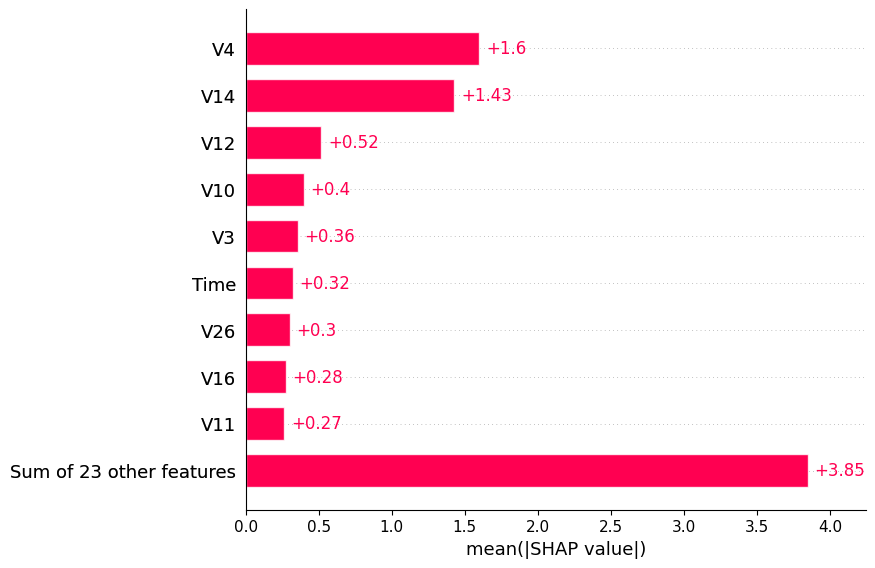

In [20]:
import shap

explainer = shap.Explainer(xgb)

shap_values = explainer(x_test[:100])

shap.plots.bar(shap_values)